# Laboratory 6: Image Thresholding and Image Segmentation

1. Global vs. Local (Adaptive) Thresholding
2. Otsu's Optimum Thresholding
3. Adaptive Thresholding (Mean & Gaussian)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import deque
from scipy.ndimage import gaussian_filter

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.labelsize'] = 9

## Synthetic Image Generation

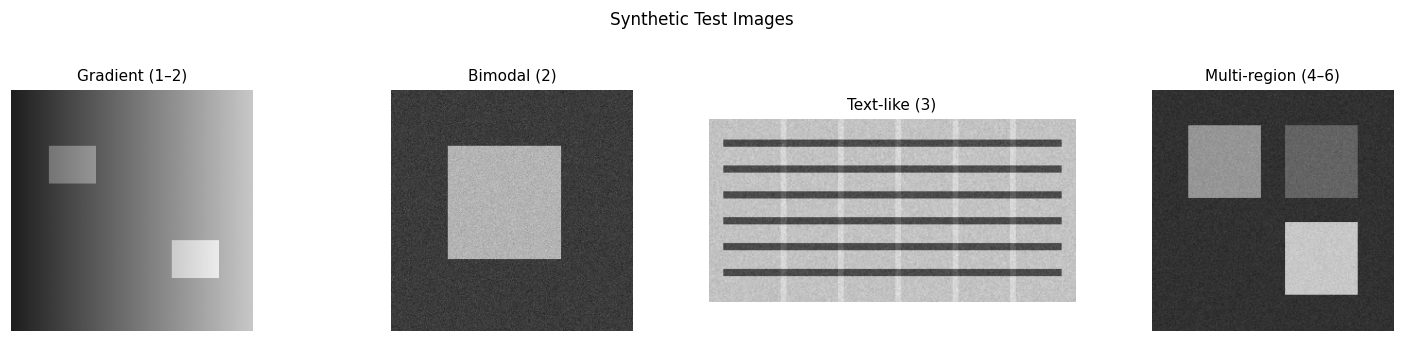

In [ ]:
def make_gradient_image(h=256, w=256):
    bg = np.linspace(30, 200, w, dtype=np.float32)
    img = np.tile(bg, (h, 1))
    img[60:100, 40:90]   += 60
    img[160:200, 170:220] += 60
    return np.clip(img, 0, 255).astype(np.uint8)

def make_bimodal_image(h=256, w=256, noise=8):
    rng = np.random.default_rng(42)
    img = np.full((h, w), 60, dtype=np.float32)
    img[60:180, 60:180] = 180
    img += rng.normal(0, noise, (h, w))
    return np.clip(img, 0, 255).astype(np.uint8)

def make_text_like_image(h=128, w=256):
    rng = np.random.default_rng(0)
    bg = gaussian_filter(rng.uniform(160, 230, (h, w)).astype(np.float32), sigma=30)
    img = bg.copy()
    for r in range(15, h-10, 18):
        img[r:r+5, 10:w-10] -= 120
    for c in range(50, w-10, 40):
        img[:, c:c+4] += 20
    img += rng.normal(0, 6, (h, w))
    return np.clip(img, 0, 255).astype(np.uint8)

def make_region_image(h=200, w=200):
    rng = np.random.default_rng(7)
    img = np.full((h, w), 50, dtype=np.float32)
    img[30:90,  30:90]  = 150
    img[110:170, 110:170] = 200
    img[30:90,  110:170] = 100
    img += rng.normal(0, 5, (h, w))
    return np.clip(img, 0, 255).astype(np.uint8)

img_grad   = make_gradient_image()
img_bm     = make_bimodal_image()
img_text   = make_text_like_image()
img_region = make_region_image()

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, im, title in zip(axes,
                         [img_grad, img_bm, img_text, img_region],
                         ['Gradient (1-2)', 'Bimodal (2)', 'Text-like (3)', 'Multi-region (4-6)']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle('Synthetic Test Images', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

## Global vs. Local (Adaptive) Thresholding

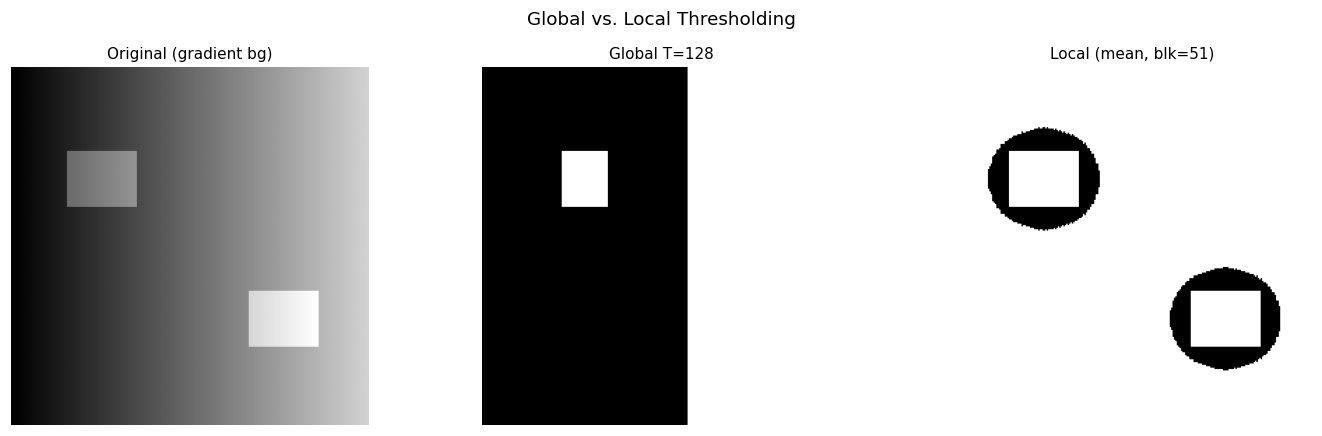

Observation: Global threshold recovers only the left object (dark bg region).
Local threshold correctly isolates BOTH objects regardless of background brightness.


In [ ]:
def global_thresh(img, T):
    return (img >= T).astype(np.uint8) * 255

def local_thresh_mean(img, blk=31, C=10):
    pad = blk // 2
    padded = np.pad(img.astype(np.float32), pad, mode='reflect')
    h, w = img.shape
    ii = np.zeros((padded.shape[0]+1, padded.shape[1]+1), dtype=np.float64)
    ii[1:, 1:] = padded.cumsum(axis=0).cumsum(axis=1)
    r0 = np.arange(h)
    r1 = r0 + blk
    c0 = np.arange(w)
    c1 = c0 + blk
    R1 = (ii[np.ix_(r1, c1)] - ii[np.ix_(r0, c1)]
        - ii[np.ix_(r1, c0)] + ii[np.ix_(r0, c0)])
    mu = R1 / (blk * blk)
    return ((img.astype(np.float32)) >= (mu - C)).astype(np.uint8) * 255

T_global = 128
bin_global = global_thresh(img_grad, T=T_global)
bin_local  = local_thresh_mean(img_grad, blk=51, C=10)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img_grad, cmap='gray')
axes[0].set_title('Original (gradient bg)')
axes[0].axis('off')
axes[1].imshow(bin_global, cmap='gray')
axes[1].set_title(f'Global T={T_global}')
axes[1].axis('off')
axes[2].imshow(bin_local,  cmap='gray')
axes[2].set_title('Local (mean, blk=51)')
axes[2].axis('off')
plt.suptitle('Global vs. Local Thresholding', fontsize=12)
plt.tight_layout()
plt.show()

print("Observation: Global threshold recovers only the left object (dark bg region).")
print("Local threshold correctly isolates BOTH objects regardless of background brightness.")

# Otsu's Optimum Thresholding

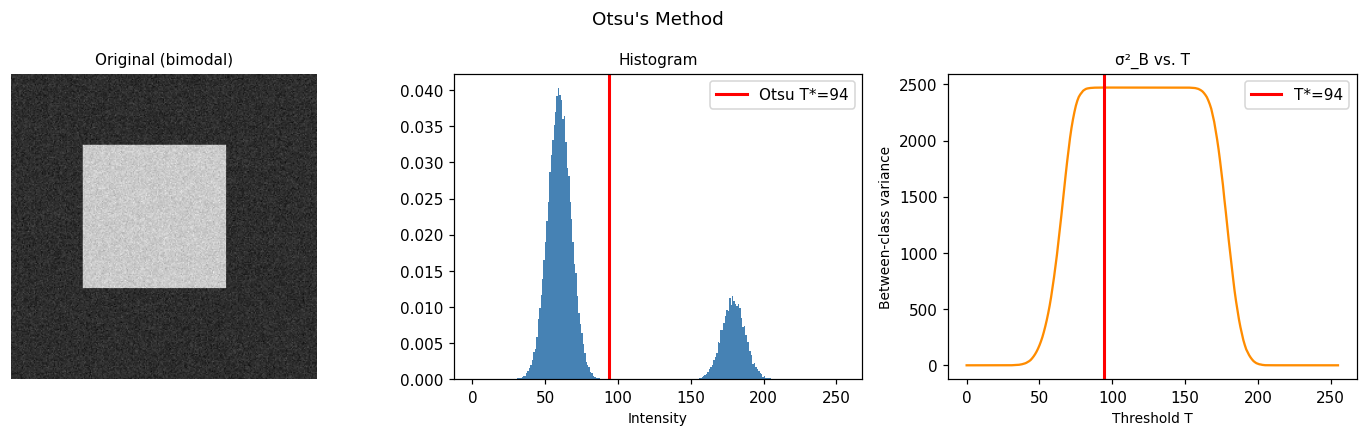

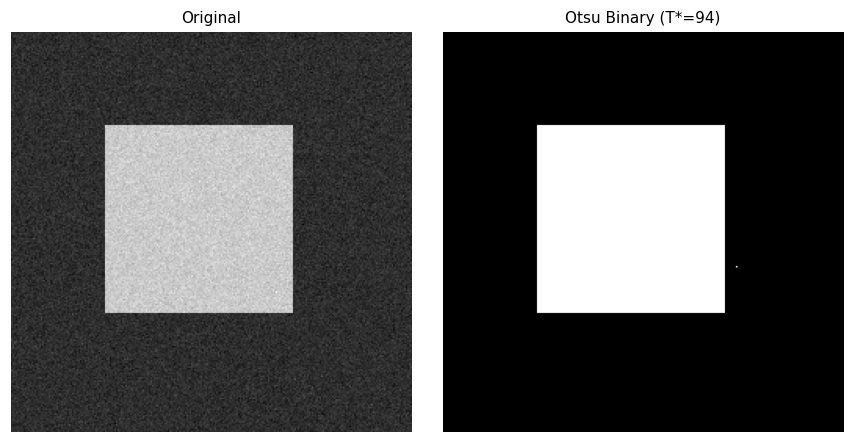

Otsu optimal threshold: T* = 94
Expected: roughly 120 (midpoint between object~180 and background~60).


In [11]:
def otsu_threshold(img):
    hist, bins = np.histogram(img.ravel(), bins=256, range=(0, 255))
    p = hist / hist.sum()
    levels = np.arange(256)

    w0 = np.cumsum(p)
    w1 = 1.0 - w0
    mu0 = np.cumsum(p * levels) / np.maximum(w0, 1e-9)
    mu_total = (p * levels).sum()
    mu1 = (mu_total - np.cumsum(p * levels)) / np.maximum(w1, 1e-9)

    sig_b2 = w0 * w1 * (mu0 - mu1) ** 2
    T_star = int(np.argmax(sig_b2))
    return T_star, sig_b2

T_otsu, sig_curve = otsu_threshold(img_bm)
bin_otsu = global_thresh(img_bm, T=T_otsu)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img_bm, cmap='gray')
axes[0].set_title('Original (bimodal)')
axes[0].axis('off')

axes[1].hist(img_bm.ravel(), bins=256, range=(0,255), color='steelblue', density=True)
axes[1].axvline(T_otsu, color='red', lw=2, label=f'Otsu T*={T_otsu}')
axes[1].set_title('Histogram')
axes[1].set_xlabel('Intensity')
axes[1].legend()

axes[2].plot(sig_curve, color='darkorange')
axes[2].axvline(T_otsu, color='red', lw=2, label=f'T*={T_otsu}')
axes[2].set_title('σ²_B vs. T')
axes[2].set_xlabel('Threshold T')
axes[2].set_ylabel('Between-class variance')
axes[2].legend()

plt.suptitle("Otsu's Method", fontsize=12)
plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, 2, figsize=(8, 4))
axes2[0].imshow(img_bm,   cmap='gray')
axes2[0].set_title('Original')
axes2[0].axis('off')
axes2[1].imshow(bin_otsu, cmap='gray')
axes2[1].set_title(f'Otsu Binary (T*={T_otsu})')
axes2[1].axis('off')
plt.tight_layout()
plt.show()

print(f"Otsu optimal threshold: T* = {T_otsu}")
print("Expected: roughly 120 (midpoint between object~180 and background~60).")

# Adaptive Thresholding (Mean & Gaussian)

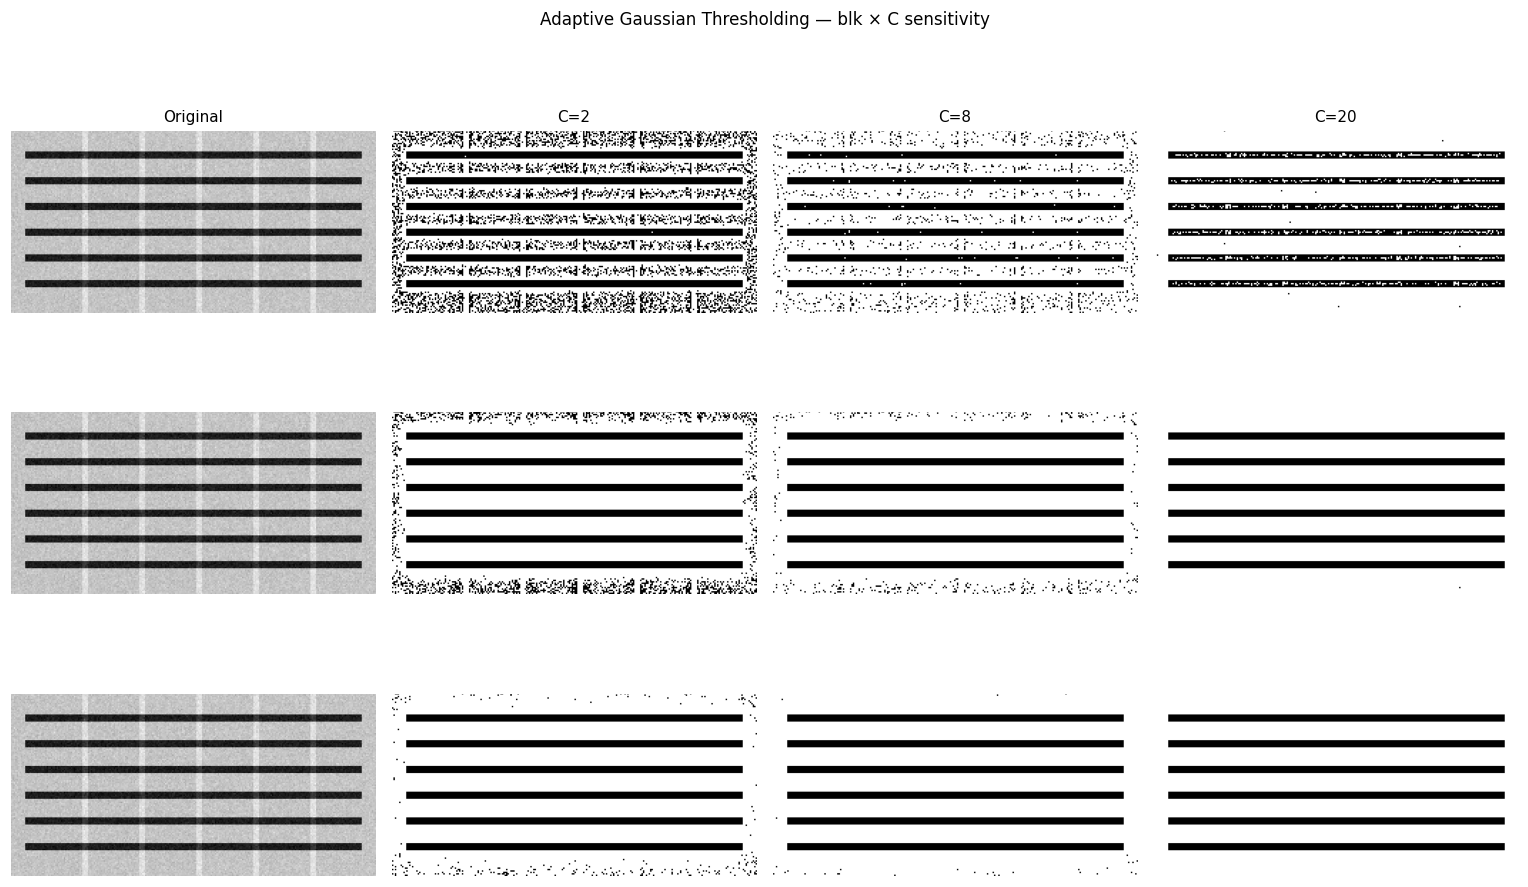

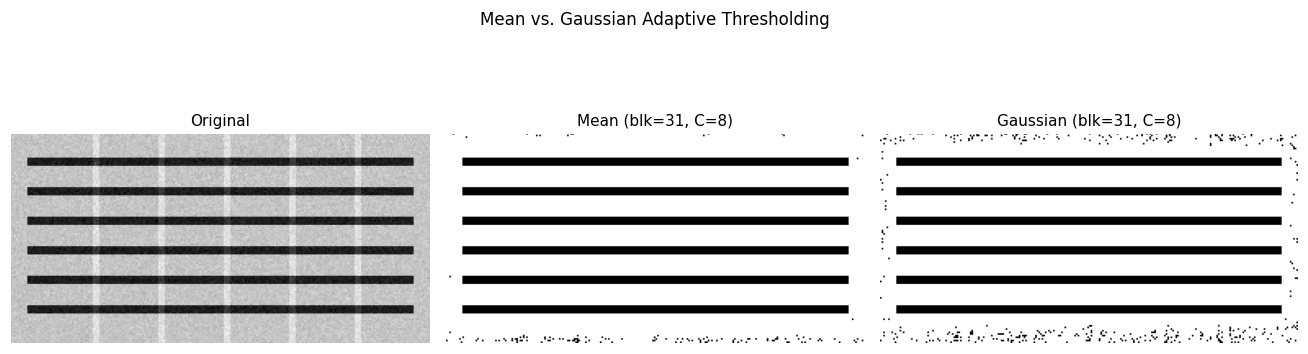

In [12]:
def adaptive_mean(img, blk=21, C=8):
    return local_thresh_mean(img, blk=blk, C=C)

def adaptive_gaussian(img, blk=21, C=8):
    sigma = blk / 6.0
    mu = gaussian_filter(img.astype(np.float32), sigma=sigma)
    return ((img.astype(np.float32)) >= (mu - C)).astype(np.uint8) * 255

blk_vals = [11, 31, 61]
C_vals   = [2, 8, 20]

fig, axes = plt.subplots(len(blk_vals), len(C_vals) + 1, figsize=(14, 9))
for i, blk in enumerate(blk_vals):
    axes[i, 0].imshow(img_text, cmap='gray')
    axes[i, 0].set_ylabel(f'blk={blk}', fontsize=9)
    axes[i, 0].axis('off')
    if i == 0: axes[i, 0].set_title('Original')
    for j, C in enumerate(C_vals):
        out = adaptive_gaussian(img_text, blk=blk, C=C)
        axes[i, j+1].imshow(out, cmap='gray')
        axes[i, j+1].axis('off')
        if i == 0: axes[i, j+1].set_title(f'C={C}')

plt.suptitle('Adaptive Gaussian Thresholding — blk × C sensitivity', fontsize=11)
plt.tight_layout()
plt.show()

blk, C = 31, 8
out_mean = adaptive_mean(img_text, blk=blk, C=C)
out_gauss = adaptive_gaussian(img_text, blk=blk, C=C)

fig2, axes2 = plt.subplots(1, 3, figsize=(12, 4))
axes2[0].imshow(img_text, cmap='gray')
axes2[0].set_title('Original')
axes2[0].axis('off')
axes2[1].imshow(out_mean, cmap='gray')
axes2[1].set_title(f'Mean (blk={blk}, C={C})')
axes2[1].axis('off')
axes2[2].imshow(out_gauss,cmap='gray')
axes2[2].set_title(f'Gaussian (blk={blk}, C={C})')
axes2[2].axis('off')
plt.suptitle('Mean vs. Gaussian Adaptive Thresholding', fontsize=11)
plt.tight_layout()
plt.show()